# Social Network Analysis Using R

This experiment uses the `igraph` package to create and visualize networks, calculate network measures, identify hubs and authorities, and detect communities in a network dataset.


## 1. Install and Load the Package

In [1]:
if (!("igraph" %in% rownames(installed.packages()))) {
  install.packages("igraph")
}

library(igraph)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘igraph’


The following objects are masked from ‘package:stats’:

    decompose, spectrum


The following object is masked from ‘package:base’:

    union




## 2. Create an Undirected Network

Warning message:
“`graph()` was deprecated in igraph 2.1.0.
ℹ Please use `make_graph()` instead.”


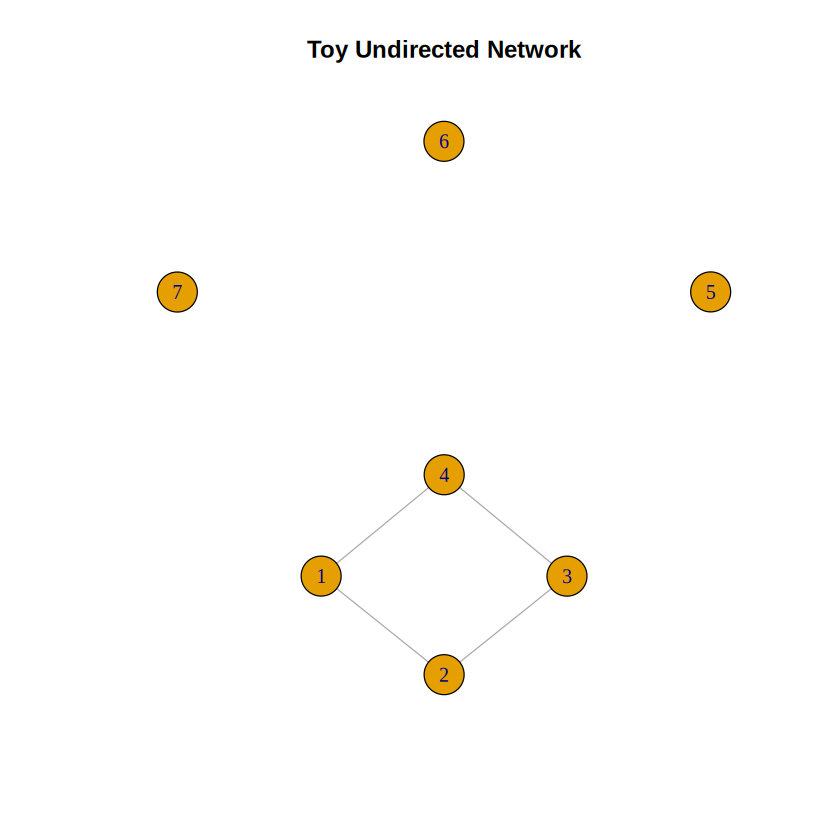

In [2]:
g <- graph(
  c(1, 2, 2, 3, 3, 4, 4, 1),
  directed = FALSE,
  n = 7
)

plot(g, main = "Toy Undirected Network")

## 3. Create a Directed Network

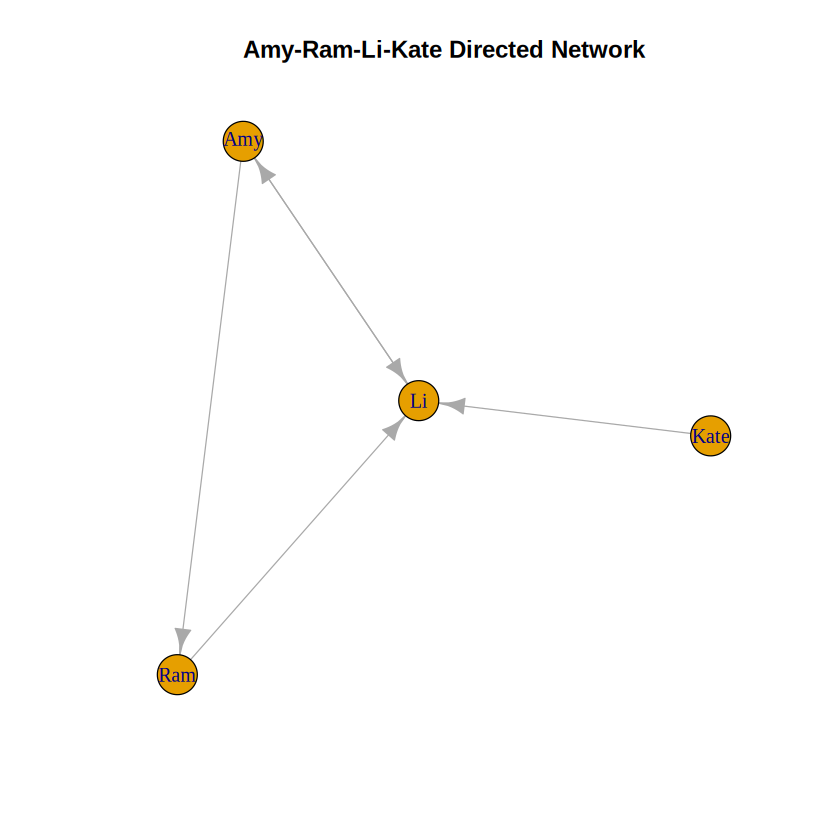

In [3]:
g1 <- graph(
  c("Amy", "Ram", "Ram", "Li", "Li", "Amy",
    "Amy", "Li", "Kate", "Li"),
  directed = TRUE
)

plot(g1, main = "Amy-Ram-Li-Kate Directed Network")

## 4. Calculate Network Measures

In [4]:
cat("\n--- Degree (all/in/out) ---\n")
print(degree(g1, mode = "all"))
print(degree(g1, mode = "in"))
print(degree(g1, mode = "out"))

cat("\nDiameter:", diameter(g1, directed = FALSE, weights = NA), "\n")

cat("Edge density (built-in):", edge_density(g1, loops = FALSE), "\n")
cat(
  "Edge density (manual check):",
  ecount(g1) / (vcount(g1) * (vcount(g1) - 1)),
  "\n"
)

cat("Reciprocity:", reciprocity(g1), "\n")

cat("\n--- Closeness centrality ---\n")
print(closeness(g1, mode = "all", weights = NA))

cat("\n--- Betweenness centrality (nodes) ---\n")
print(betweenness(g1, directed = TRUE, weights = NA))

cat("\n--- Edge betweenness ---\n")
print(edge_betweenness(g1, directed = TRUE, weights = NA))


--- Degree (all/in/out) ---
 Amy  Ram   Li Kate 
   3    2    4    1 
 Amy  Ram   Li Kate 
   1    1    3    0 
 Amy  Ram   Li Kate 
   2    1    1    1 

Diameter: 2 
Edge density (built-in): 0.4166667 
Edge density (manual check): 0.4166667 
Reciprocity: 0.4 

--- Closeness centrality ---
      Amy       Ram        Li      Kate 
0.2500000 0.2500000 0.3333333 0.2000000 

--- Betweenness centrality (nodes) ---
 Amy  Ram   Li Kate 
   2    0    3    0 

--- Edge betweenness ---
[1] 3 2 5 1 3


## 5. Import the Network Dataset

In [5]:
data <- read.csv(
  "https://raw.githubusercontent.com/bkrai/R-files-from-YouTube/main/networkdata.csv",
  header = TRUE
)

y <- data.frame(data$first, data$second)
head(y)

,data.first,data.second
,<chr>,<chr>
1,AA,DD
2,AB,DD
3,AF,BA
4,DD,DA
5,CD,EC
6,DD,CE


## 6. Create and Explore the Network

In [6]:
net <- graph.data.frame(y, directed = TRUE)

V(net)$label <- V(net)$name
V(net)$degree <- degree(net)

cat("Number of nodes:", vcount(net), "\n")
cat("Number of edges:", ecount(net), "\n")

Warning message:
“`graph.data.frame()` was deprecated in igraph 2.0.0.
ℹ Please use `graph_from_data_frame()` instead.”


Number of nodes: 52 
Number of edges: 290 


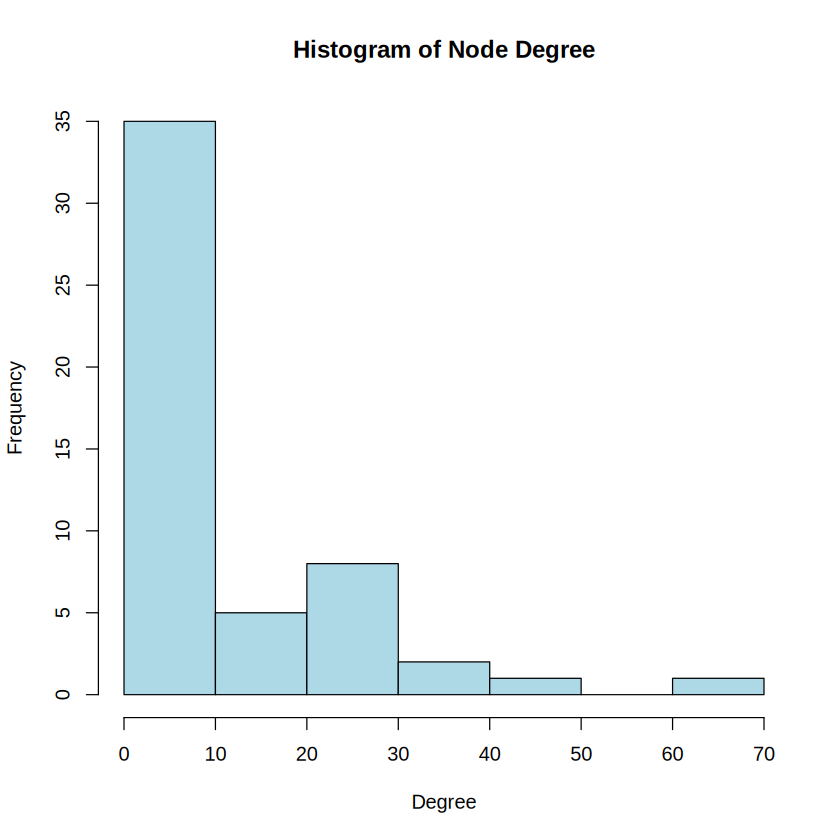

In [7]:
hist(
  V(net)$degree,
  main = "Histogram of Node Degree",
  xlab = "Degree",
  col = "lightblue"
)

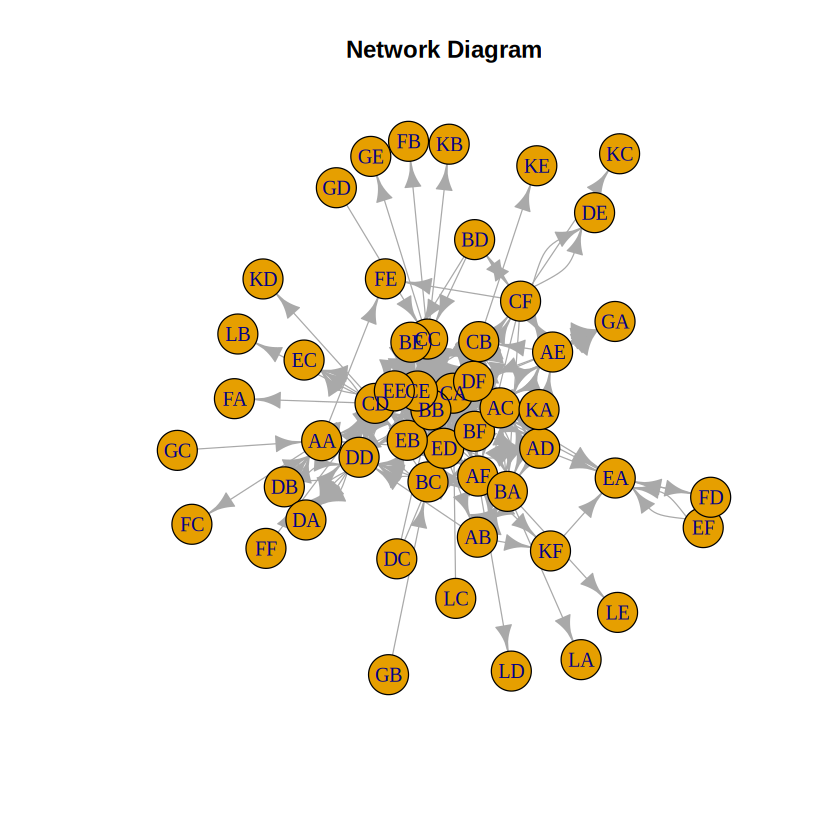

In [8]:
plot(net, main = "Network Diagram")

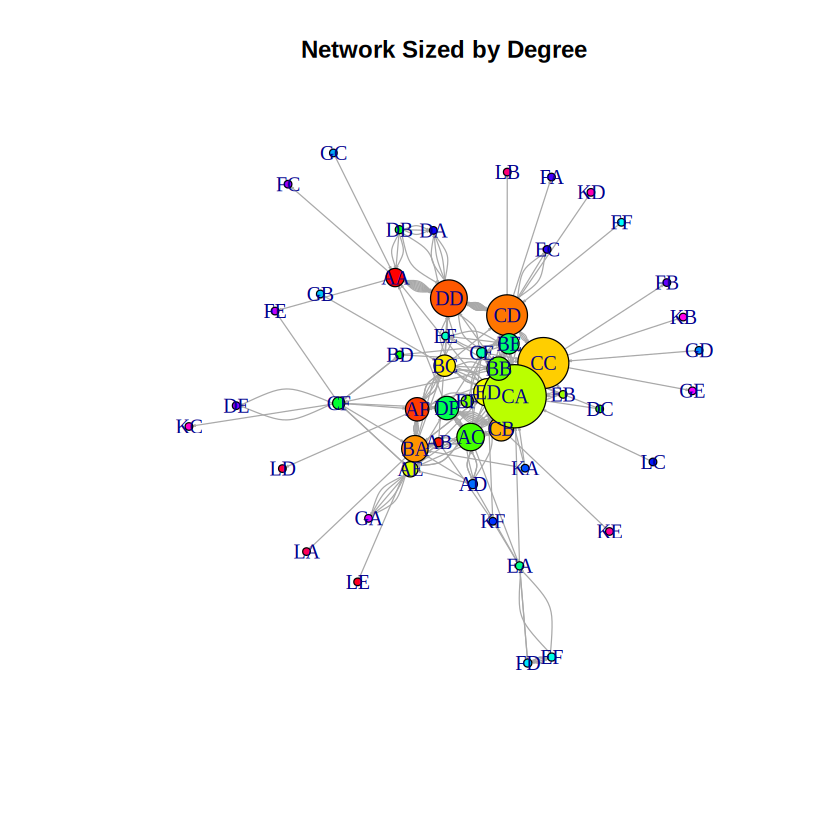

In [9]:
plot(
  net,
  vertex.color = rainbow(vcount(net)),
  vertex.size = pmax(V(net)$degree * 0.4, 3),
  edge.arrow.size = 0.1,
  layout = layout_with_fr,
  main = "Network Sized by Degree"
)

## 7. Calculate Hub and Authority Scores

Warning message:
“`hub_score()` was deprecated in igraph 2.0.3.
ℹ Please use `hits_scores()` instead.”
Warning message:
“`authority.score()` was deprecated in igraph 2.0.0.
ℹ Please use `hits_scores()` instead.”


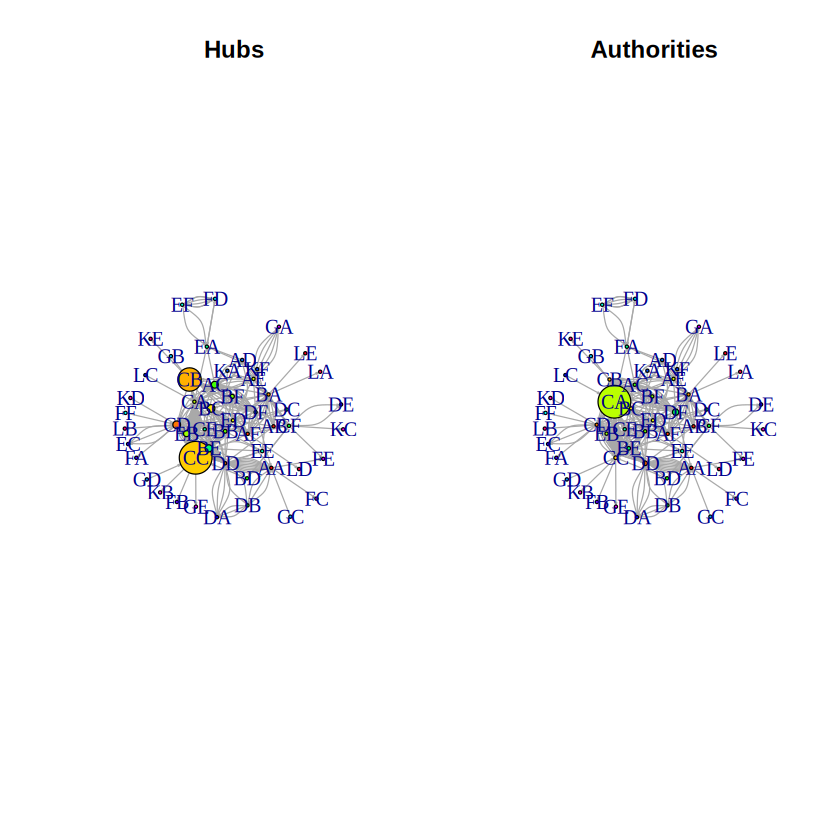

In [10]:
hs <- hub_score(net)$vector
auth <- authority.score(net)$vector

par(mfrow = c(1, 2))
set.seed(123)

plot(
  net,
  vertex.size = pmax(hs * 30, 3),
  vertex.color = rainbow(vcount(net)),
  edge.arrow.size = 0.1,
  layout = layout_with_kk,
  main = "Hubs"
)

plot(
  net,
  vertex.size = pmax(auth * 30, 3),
  vertex.color = rainbow(vcount(net)),
  edge.arrow.size = 0.1,
  layout = layout_with_kk,
  main = "Authorities"
)

par(mfrow = c(1, 1))

In [11]:
cat("\nTop 5 Hubs:\n")
print(head(sort(hs, decreasing = TRUE), 5))

cat("\nTop 5 Authorities:\n")
print(head(sort(auth, decreasing = TRUE), 5))


Top 5 Hubs:
       CC        CB        CD        BC        BE 
1.0000000 0.7145888 0.2350165 0.2321828 0.2195271 

Top 5 Authorities:
       CA        DF        DD        CC        BE 
1.0000000 0.1925650 0.1409698 0.1121941 0.1095155 


## 8. Detect Communities

Warning message:
“`as.undirected()` was deprecated in igraph 2.1.0.
ℹ Please use `as_undirected()` instead.”



Number of communities detected: 16 
Modularity score: 0.2570863 


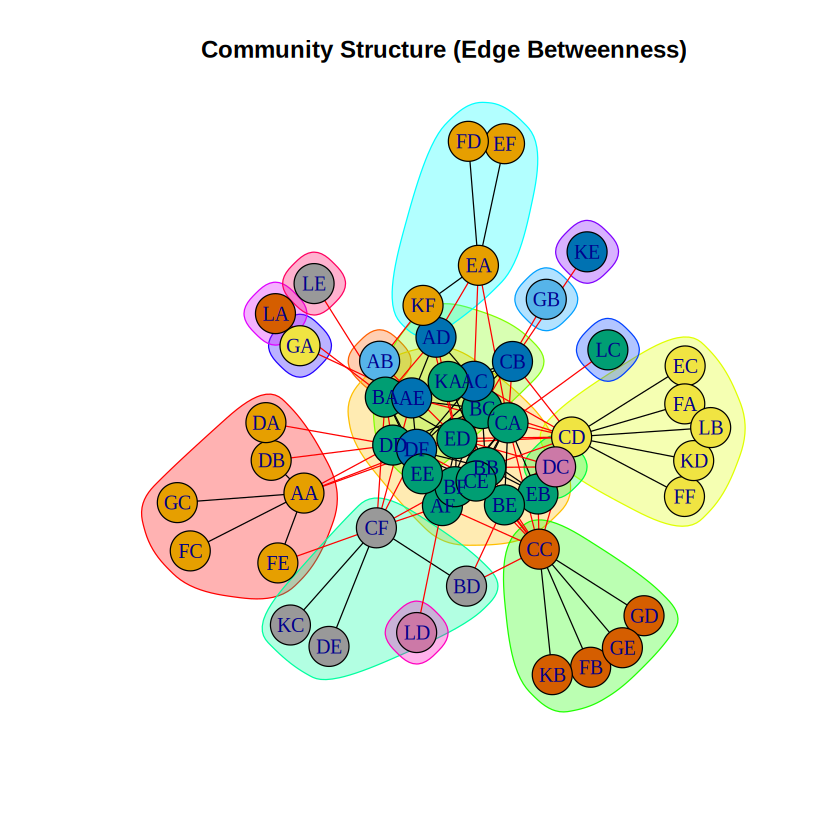

In [12]:
net_undirected <- as.undirected(net, mode = "collapse")
cnet <- cluster_edge_betweenness(net_undirected)

plot(cnet, net_undirected, main = "Community Structure (Edge Betweenness)")

cat("\nNumber of communities detected:", length(cnet), "\n")
cat("Modularity score:", modularity(cnet), "\n")

## 9. Summarize the Results

In [13]:
top_degree_node <- names(sort(degree(net), decreasing = TRUE))[1]
top_hub_node <- names(sort(hs, decreasing = TRUE))[1]
top_auth_node <- names(sort(auth, decreasing = TRUE))[1]

cat("\n================= INTERPRETATION =================\n")
cat("1. The imported network has", vcount(net), "nodes and", ecount(net), "edges.\n")
cat("2. Node '", top_degree_node, "' has the highest overall degree.\n", sep = "")
cat("3. Node '", top_hub_node, "' has the highest hub score.\n", sep = "")
cat("4. Node '", top_auth_node, "' has the highest authority score.\n", sep = "")
cat("5. Community detection found", length(cnet), "communities.\n")
cat("   Modularity score:", round(modularity(cnet), 3), "\n")
cat("====================================================\n")


================= INTERPRETATION =================
1. The imported network has 52 nodes and 290 edges.
2. Node 'CA' has the highest overall degree.
3. Node 'CC' has the highest hub score.
4. Node 'CA' has the highest authority score.
5. Community detection found 16 communities.
   Modularity score: 0.257 
